# Semillero AD Universidad EIA
# Challenge 2026-1: Survival Analysis

**Objective:** do a survival analysis of the `rossi` dataset from the `lifelines` package.

The `rossi` dataset comes from a study about the recidivism of 432 prisoners followed for 52 weeks after their release. The time variable is `week` (week of the first arrest) and the event variable is `arrest` (1 = arrested, 0 = censored).

Base libraries of the project: `pandas`, `numpy`, `seaborn`, `matplotlib` and `lifelines`.

## Part 1. Installing the lifelines package

In [1]:
!pip install lifelines
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
%matplotlib inline


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\lezqu\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


## Part 2. Loading and exploring the dataset

We import `rossi` from the `lifelines` datasets, read it as a `DataFrame` and check its variables with `info` and `describe`.

In [2]:
from lifelines.datasets import load_rossi

rossi = load_rossi()
rossi.head()

,week,arrest,fin,age,race,wexp,mar,paro,prio
0,20,1,0,27,1,0,0,1,3
1,17,1,0,18,1,0,0,1,8
2,25,1,0,19,0,1,0,1,13
3,52,0,1,23,1,1,1,1,1
4,52,0,0,19,0,1,0,1,3


In [3]:
rossi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 432 entries, 0 to 431
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   week    432 non-null    int64
 1   arrest  432 non-null    int64
 2   fin     432 non-null    int64
 3   age     432 non-null    int64
 4   race    432 non-null    int64
 5   wexp    432 non-null    int64
 6   mar     432 non-null    int64
 7   paro    432 non-null    int64
 8   prio    432 non-null    int64
dtypes: int64(9)
memory usage: 30.5 KB


In [4]:
rossi.describe()

,week,arrest,fin,age,race,wexp,mar,paro,prio
count,432.000000,432.000000,432.00000,432.000000,432.000000,432.000000,432.000000,432.000000,432.000000
mean,45.854167,0.263889,0.50000,24.597222,0.877315,0.571759,0.122685,0.618056,2.983796
std,12.662293,0.441251,0.50058,6.113375,0.328456,0.495398,0.328456,0.486426,2.896068
min,1.000000,0.000000,0.00000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,50.000000,0.000000,0.00000,20.000000,1.000000,0.000000,0.000000,0.000000,1.000000
50%,52.000000,0.000000,0.50000,23.000000,1.000000,1.000000,0.000000,1.000000,2.000000
75%,52.000000,1.000000,1.00000,27.000000,1.000000,1.000000,0.000000,1.000000,4.000000
max,52.000000,1.000000,1.00000,44.000000,1.000000,1.000000,1.000000,1.000000,18.000000


The 9 variables are numeric (`int64`) and there are no missing values:

- `week`: week of the first arrest (1 to 52).
- `arrest`: observed event (1 = arrest, 0 = censored).
- `fin`: financial aid after the release (1 = yes, 0 = no).
- `age`: age in years at the release.
- `race`: 1 = black, 0 = other.
- `wexp`: previous work experience (1 = yes).
- `mar`: married (1 = yes).
- `paro`: released on parole (1 = yes).
- `prio`: number of previous convictions.

In [5]:
T = rossi["week"]
E = rossi["arrest"]

print("Observations:", len(rossi))
print("Events (arrests):", int(E.sum()))
print("Censored:", int((E == 0).sum()))
print("Arrest rate:", round(E.mean(), 4))

Observations: 432
Events (arrests): 114
Censored: 318
Arrest rate: 0.2639


## Part 3. Kaplan-Meier model

We fit the non-parametric Kaplan-Meier estimator and plot the survival function using `week` and `arrest`.

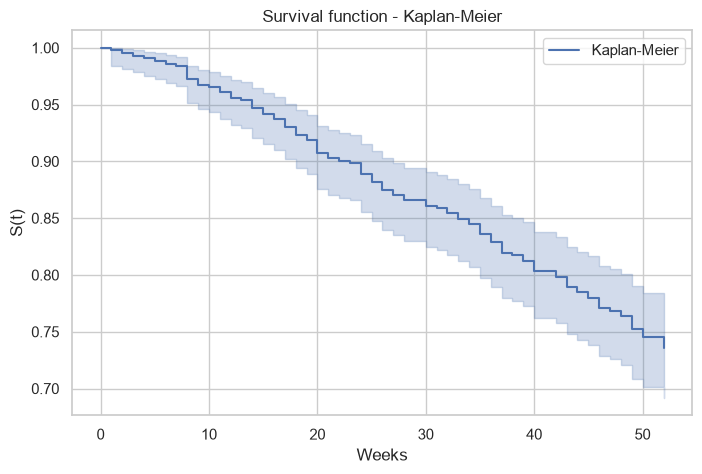

In [6]:
from lifelines import KaplanMeierFitter

kmf = KaplanMeierFitter()
kmf.fit(T, event_observed=E, label="Kaplan-Meier")

plt.figure(figsize=(8, 5))
kmf.plot_survival_function()
plt.title("Survival function - Kaplan-Meier")
plt.xlabel("Weeks")
plt.ylabel("S(t)")
plt.show()

In [7]:
print("Median survival time:", kmf.median_survival_time_)
kmf.survival_function_.tail()

Median survival time: inf


,Kaplan-Meier
timeline,
47.0,0.768519
48.0,0.763889
49.0,0.752315
50.0,0.745370
52.0,0.736111


The probability of not being arrested at the end of the follow-up (week 52) is approximately **0.74**. The median survival time is infinite because more than half of the individuals never have the event during the 52 weeks.

## Part 4. Log-rank test by financial aid

We split the variable `fin` in two groups: **with aid** (`fin == 1`) and **without aid** (`fin == 0`), and we apply the log-rank test on `week` and `arrest` to compare their survival curves.

In [8]:
from lifelines.statistics import logrank_test

con_ayuda = rossi[rossi["fin"] == 1]
sin_ayuda = rossi[rossi["fin"] == 0]

resultado = logrank_test(
    con_ayuda["week"], sin_ayuda["week"],
    con_ayuda["arrest"], sin_ayuda["arrest"]
)
resultado.print_summary()

In [9]:
print("Test statistic:", round(resultado.test_statistic, 4))
print("p-value:", round(resultado.p_value, 4))

Test statistic: 3.8376
p-value: 0.0501


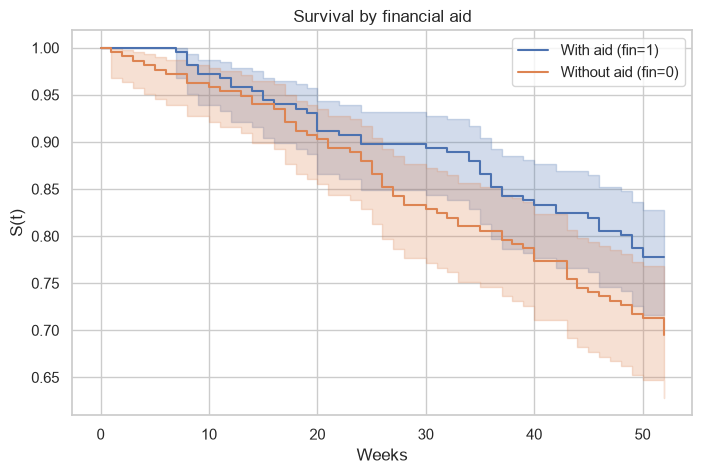

In [10]:
kmf_c = KaplanMeierFitter().fit(con_ayuda["week"], con_ayuda["arrest"], label="With aid (fin=1)")
kmf_s = KaplanMeierFitter().fit(sin_ayuda["week"], sin_ayuda["arrest"], label="Without aid (fin=0)")

plt.figure(figsize=(8, 5))
ax = kmf_c.plot_survival_function()
kmf_s.plot_survival_function(ax=ax)
plt.title("Survival by financial aid")
plt.xlabel("Weeks")
plt.ylabel("S(t)")
plt.show()

The **p-value ≈ 0.05** is just at the limit of significance. There is weak evidence that the financial aid reduces the risk of recidivism: the group with aid tends to keep a higher survival, but the difference is not conclusive at the 5% level.

## Part 5. Exponential model

We create and fit the `ExponentialFitter`, build the survival function, find the parameter $\lambda$ and evaluate the hazard and cumulative hazard functions, showing them as a `DataFrame`.

In [11]:
from lifelines import ExponentialFitter

exf = ExponentialFitter()
exf.fit(T, E, label="Exponential")
exf.print_summary()

<lifelines.ExponentialFitter:"Exponential", fitted with 432 total observations, 318 right-censored observations>
   number of observations = 432
number of events observed = 114
           log-likelihood = -701.98
               hypothesis = lambda_ != 0

---
          coef  se(coef)  coef lower 95%  coef upper 95%
lambda_ 173.76     16.27          141.87          205.66

         cmp to     z      p  -log2(p)
lambda_    0.00 10.68 <0.005     85.99
---
AIC = 1405.95

In [12]:
print("Parameter lambda:", round(exf.lambda_, 4))
print("AIC:", round(exf.AIC_, 4))

Parameter lambda: 173.7632
AIC: 1405.9541


In [13]:
exp_funcs = pd.DataFrame({
    "hazard": exf.hazard_.values.ravel(),
    "cumulative_hazard": exf.cumulative_hazard_.values.ravel()
}, index=exf.hazard_.index)
exp_funcs.index.name = "timeline"
exp_funcs.head(10)

,hazard,cumulative_hazard
timeline,,
1.000000,0.005755,0.005755
1.118329,0.005755,0.006436
1.236659,0.005755,0.007117
1.354988,0.005755,0.007798
1.473318,0.005755,0.008479
1.591647,0.005755,0.009160
1.709977,0.005755,0.009841
1.828306,0.005755,0.010522
1.946636,0.005755,0.011203


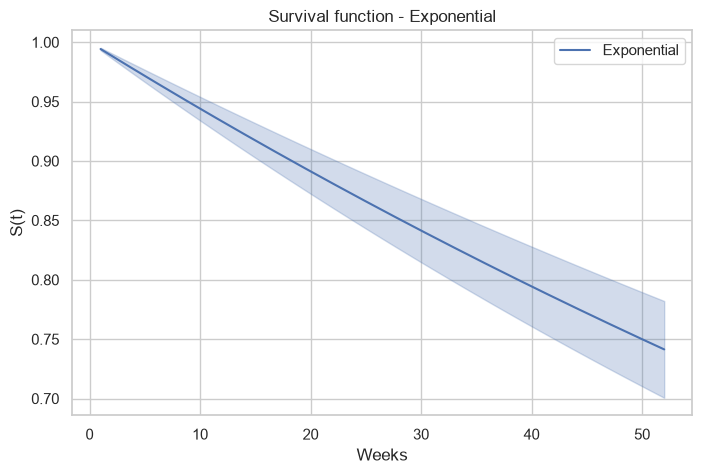

In [14]:
plt.figure(figsize=(8, 5))
exf.plot_survival_function()
plt.title("Survival function - Exponential")
plt.xlabel("Weeks")
plt.ylabel("S(t)")
plt.show()

The exponential model assumes a **constant** risk over time. The hazard function is flat and the cumulative hazard grows linearly.

## Part 6. Weibull model

We create and fit the `WeibullFitter`, build the survival function, find the parameters $\lambda$ and $\rho$, and show the hazard and cumulative hazard functions as a `DataFrame`.

In [15]:
from lifelines import WeibullFitter

wbf = WeibullFitter()
wbf.fit(T, E, label="Weibull")
wbf.print_summary()

<lifelines.WeibullFitter:"Weibull", fitted with 432 total observations, 318 right-censored observations>
   number of observations = 432
number of events observed = 114
           log-likelihood = -696.62
               hypothesis = lambda_ != 1, rho_ != 1

---
          coef  se(coef)  coef lower 95%  coef upper 95%
lambda_ 123.68     13.34           97.53          149.83
rho_      1.37      0.12            1.12            1.61

         cmp to    z      p  -log2(p)
lambda_    1.00 9.19 <0.005     64.53
rho_       1.00 2.96 <0.005      8.36
---
AIC = 1397.25

In [16]:
print("Parameter lambda:", round(wbf.lambda_, 4))
print("Parameter rho:", round(wbf.rho_, 4))
print("AIC:", round(wbf.AIC_, 4))

Parameter lambda: 123.6771
Parameter rho: 1.3651
AIC: 1397.2488


In [17]:
wb_funcs = pd.DataFrame({
    "hazard": wbf.hazard_.values.ravel(),
    "cumulative_hazard": wbf.cumulative_hazard_.values.ravel()
}, index=wbf.hazard_.index)
wb_funcs.index.name = "timeline"
wb_funcs.head(10)

,hazard,cumulative_hazard
timeline,,
1.000000,0.001901,0.001392
1.118329,0.001980,0.001622
1.236659,0.002054,0.001861
1.354988,0.002124,0.002108
1.473318,0.002190,0.002363
1.591647,0.002252,0.002626
1.709977,0.002312,0.002896
1.828306,0.002369,0.003173
1.946636,0.002424,0.003457


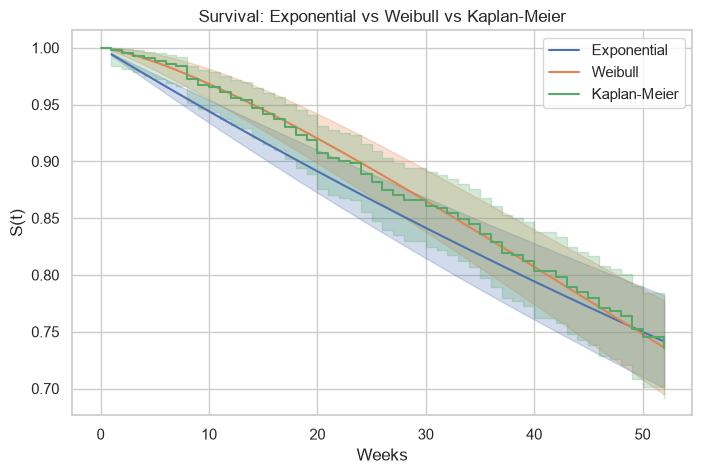

In [18]:
plt.figure(figsize=(8, 5))
ax = exf.plot_survival_function()
wbf.plot_survival_function(ax=ax)
kmf.plot_survival_function(ax=ax)
plt.title("Survival: Exponential vs Weibull vs Kaplan-Meier")
plt.xlabel("Weeks")
plt.ylabel("S(t)")
plt.show()

As $\rho \approx 1.37 > 1$, the Weibull model indicates a recidivism risk that **grows** over time, unlike the exponential model. Its curve fits the Kaplan-Meier curve better.

## Part 7. Cox model (CoxPHFitter)

We create and fit the Cox proportional hazards model, plot the baseline survival, show the summary, check the assumptions of the model and compare the AIC of the exponential and Weibull models.

In [19]:
from lifelines import CoxPHFitter

cph = CoxPHFitter()
cph.fit(rossi, duration_col="week", event_col="arrest")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 432 total observations, 318 right-censored observations>
             duration col = 'week'
                event col = 'arrest'
      baseline estimation = breslow
   number of observations = 432
number of events observed = 114
   partial log-likelihood = -658.75
         time fit was run = 2026-10-20 23:24:50 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
fin       -0.38      0.68      0.19           -0.75           -0.00                0.47                1.00
age       -0.06      0.94      0.02           -0.10           -0.01                0.90                0.99
race       0.31      1.37      0.31           -0.29            0.92                0.75                2.50
wexp      -0.15      0.86      0.21           -0.57            0.27                0.57                1.30
mar       -0.43      0.65      0.38           -1.18            0.31                0.31                1.37
paro      -0.08      0.92      0.20           -0.47            0.30                0.63                1.35
prio       0.09      1.10      0.03            0.04            0.15                1.04                1.16

           cmp to     z      p  -log2(p)
covariate                               
fin          0.00 -1.98   0.05      4.40
age          0.00 -2.61   0.01      6.79
race         0.00  1.02   0.31      1.70
wexp         0.00 -0.71   0.48      1.06
mar          0.00 -1.14   0.26      1.97
paro         0.00 -0.43   0.66      0.59
prio         0.00  3.19 <0.005      9.48
---
Concordance = 0.64
Partial AIC = 1331.50
log-likelihood ratio test = 33.27 on 7 df
-log2(p) of ll-ratio test = 15.37

In [20]:
print("Concordance index:", round(cph.concordance_index_, 4))

Concordance index: 0.6403


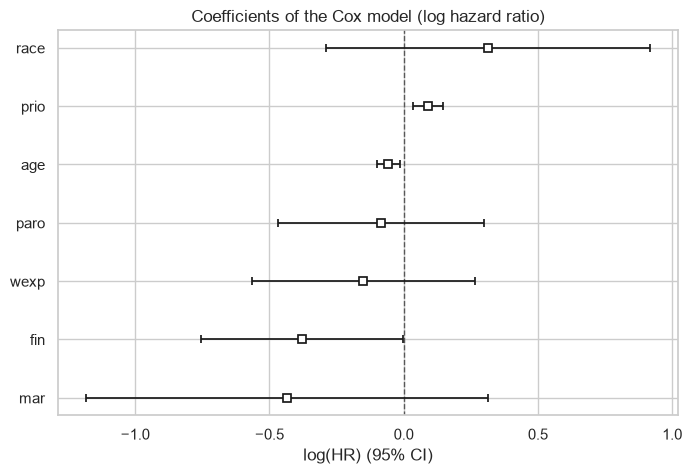

In [21]:
plt.figure(figsize=(8, 5))
cph.plot()
plt.title("Coefficients of the Cox model (log hazard ratio)")
plt.show()

<Figure size 800x500 with 0 Axes>

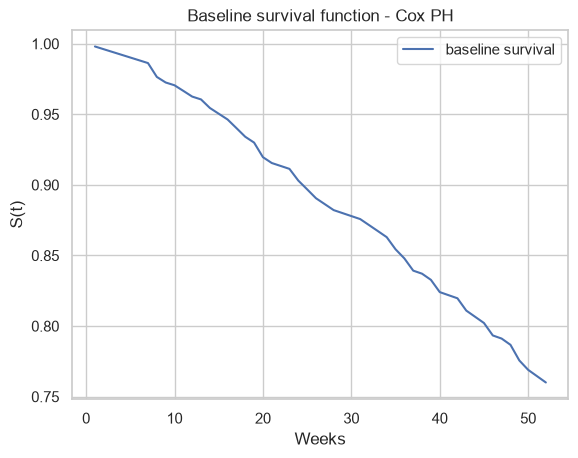

In [22]:
plt.figure(figsize=(8, 5))
cph.baseline_survival_.plot()
plt.title("Baseline survival function - Cox PH")
plt.xlabel("Weeks")
plt.ylabel("S(t)")
plt.show()

**Summary of the Cox model.** The statistically significant variables are `prio` (previous convictions, increases the risk), `age` (age reduces it) and `fin` (financial aid reduces it, at the limit). The concordance index is **0.64**.

In [23]:
cph.check_assumptions(rossi, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'age' failed the non-proportional test: p-value is 0.0007.

   Advice 1: the functional form of the variable 'age' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'age' using pd.cut, and then specify it in `strata=['age',
...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'wexp' failed the non-proportional test: p-value is 0.0063.

   Advice: with so few unique values (only 2), you can include `strata=['wexp', ...]` in the call in
`.fit`. See documentation in link [E] below.

---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/lat

[]

**Checking the assumptions.** The proportional hazards test shows that `age` and `wexp` do not fully meet the proportionality assumption (p < 0.05), so a more refined model could stratify by those variables.

### Comparison of the parametric models (AIC)

We compare the performance of the exponential and Weibull models with the Akaike information criterion (AIC): the lower the AIC, the better the fit.

In [24]:
comparacion = pd.DataFrame({
    "Model": ["Exponential", "Weibull"],
    "AIC": [round(exf.AIC_, 4), round(wbf.AIC_, 4)]
})
comparacion

,Model,AIC
0,Exponential,1405.9541
1,Weibull,1397.2488


In [25]:
mejor = "Weibull" if wbf.AIC_ < exf.AIC_ else "Exponential"
print("Model with the best performance (lowest AIC):", mejor)

Model with the best performance (lowest AIC): Weibull


## Conclusions

1. The **Kaplan-Meier** estimator shows that around 74% of the individuals do not reoffend during the 52 weeks of follow-up.
2. The **log-rank test** on financial aid gives a p-value close to 0.05: there is a weak protective effect, but it is not conclusive at 5%.
3. The **Weibull model** ($\rho \approx 1.37$) captures a risk that grows over time and gets a **lower AIC (1397.25)** than the **exponential (1405.95)**, so it fits the data better.
4. The **Cox model** identifies previous convictions (`prio`), age (`age`) and financial aid (`fin`) as the most relevant factors, although `age` and `wexp` do not fully meet the proportional hazards assumption.

**Between exponential and Weibull, the Weibull model has the best performance.**